# Effects of coherent bending on PSF

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import yaml

from iactrace import Telescope
from iactrace.analysis import FlatFocalPlane
from iactrace.core.transforms import euler_to_matrix

ROUGHNESS = 2.0        # arcsec
FOCAL_SPREAD = 0.074   # m

key1, key2 = jax.random.split(jax.random.key(13), 3)[:2]
aligned = (
    Telescope.from_yaml("../../configs/HESS/CT3.yaml", n_samples=256, key=key1)
    .apply_roughness(0, ROUGHNESS)
    .apply_focal_error(0, FOCAL_SPREAD, key2)
)

ON_AXIS = jnp.array([[0.0, 0.0, -1.0]])
ARCSEC_PER_MM = 206265.0 / 15000.0  # 15 m focal length
MRAD = 206.265                      # arcsec


def spot(tel, dz=0.0, distance=None):
    """Spot trace with information
    """
    if distance is None:
        bundle = tel.render(ON_AXIS, jnp.array([1.0]), "parallel")
    else:
        bundle = tel.render(jnp.array([[0.0, 0.0, distance]]), jnp.array([1.0]), "point")
    hits = FlatFocalPlane(position=[0.0, 0.0, dz]).intersect(bundle)
    m = hits.alive
    xy = np.asarray(hits.xy_local[m])[:, ::-1] * 1000.0 * ARCSEC_PER_MM
    w = np.asarray(hits.values[m])
    return xy - (w[:, None] * xy).sum(0) / w.sum(), w


def widths(tel, dz=0.0, distance=None):
    """RMS width of the image along lon and lat, in arcsec."""
    xy, w = spot(tel, dz, distance)
    return np.sqrt((w[:, None] * xy**2).sum(0) / w.sum())


# Camera pixel size and shape

_cam = yaml.safe_load(open("../../configs/HESS/HESS1U.yaml"))["sensors"][0]
_c = np.c_[_cam["centers_x"], _cam["centers_y"]]
_d = np.hypot(*(_c[:, None] - _c[None]).transpose(2, 0, 1))
np.fill_diagonal(_d, np.inf)
PIXEL_APOTHEM = 0.5 * _d.min() * 1000.0 * ARCSEC_PER_MM  # arcsec


def draw_pixel(ax):
    r = PIXEL_APOTHEM / np.cos(np.pi / 6)
    ang = np.radians(np.arange(0, 361, 60))
    ax.plot(r * np.cos(ang), r * np.sin(ang), color="white", lw=1.0, alpha=0.8)

## Focus at infinity compared to lid

starlight focus (lid) 2.8 cm in front of the pixels


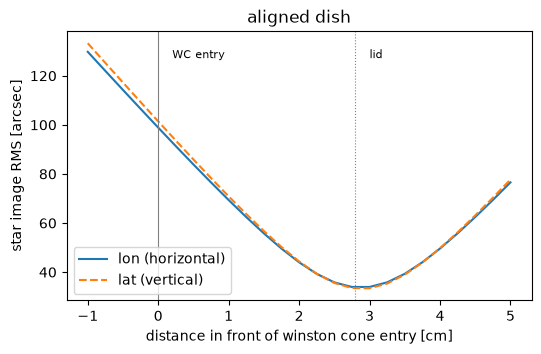

In [2]:
dz = np.linspace(-0.01, 0.05, 25)
w_al = np.array([widths(aligned, d) for d in dz])
lid = 0.028
print(f"starlight focus (lid) {100 * lid:.1f} cm in front of the pixels")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(100 * dz, w_al[:, 0], label="lon (horizontal)")
ax.plot(100 * dz, w_al[:, 1], label="lat (vertical)", ls="--")
ax.axvline(0, color="grey", lw=0.8)
ax.axvline(100 * lid, color="grey", lw=0.8, ls=":")
ax.text(0.2, ax.get_ylim()[1] * 0.92, "WC entry", fontsize=8)
ax.text(100 * lid + 0.2, ax.get_ylim()[1] * 0.92, "lid", fontsize=8)
ax.set(xlabel="distance in front of winston cone entry [cm]", ylabel="star image RMS [arcsec]", title="aligned dish")
ax.legend(loc="lower left")
plt.show()

## Random vs Coherent Bending

- **random**: independent Gaussian facet tilts
- **saddle + random**: facet tilts with a saddle pattern like in Cornils 2003 + random component

Parameters are chosen so that the image on the lid looks the same.

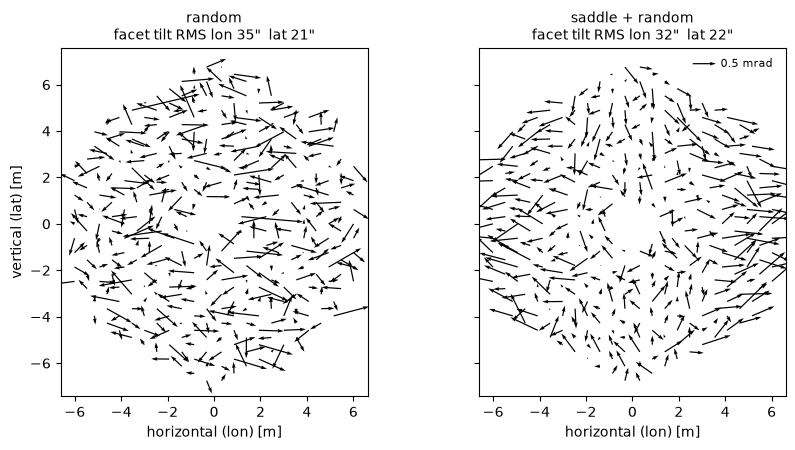

In [3]:
pos = np.asarray(aligned.stage(0).positions)
x, y = pos[:, 0], pos[:, 1]


def bend(tel, h=0.0, v=0.0):
    """Facet tilts growing linearly across the dish: h along lon, v along lat, arcsec RMS.

    Positive tilts the facets towards the dish axis, negative away from it.
    """
    rot = np.asarray(tel.stage(0).rotations).copy()
    rot[:, 0] += h / 3600.0 * y / np.sqrt(np.mean(y**2))
    rot[:, 1] -= v / 3600.0 * x / np.sqrt(np.mean(x**2))
    return tel.set_rotations(0, jnp.asarray(rot))


edge = 6.0  # m
saddle_h = -0.25 * MRAD * np.sqrt(np.mean(y**2)) / edge  # outwards horizontally
saddle_v = +0.10 * MRAD * np.sqrt(np.mean(x**2)) / edge  # inwards vertically

dishes = {
    "random": aligned.apply_misalignment(0, sigma_h=20.0, sigma_v=35.0, key=jax.random.key(11)),
    "saddle + random": bend(
        aligned.apply_misalignment(0, sigma_h=19.0, sigma_v=19.0, key=jax.random.key(12)),
        h=saddle_h, v=saddle_v,
    ),
}

def normals(tel):
    return np.asarray(jax.vmap(euler_to_matrix)(tel.stage(0).rotations))[:, :, 2]


n_aligned = normals(aligned)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharex=True, sharey=True)
for a, (name, tel) in zip(axes, dishes.items(), strict=False):
    shift = 2e3 * (normals(tel) - n_aligned)  # mrad on the lid; columns x (lat), y (lon)
    a.quiver(y, x, shift[:, 1], shift[:, 0], angles="xy", scale_units="xy", scale=0.5, width=0.004)
    rms = np.sqrt(np.mean(shift[:, :2] ** 2, axis=0)) / 2 * MRAD  # back to a facet tilt in arcsec
    a.set_title(f"{name}\nfacet tilt RMS lon {rms[1]:.0f}\"  lat {rms[0]:.0f}\"", fontsize=10)
    a.set_aspect("equal")
    a.set_xlabel("horizontal (lon) [m]")
axes[0].set_ylabel("vertical (lat) [m]")
# scale: an arrow of 0.5 mrad in an empty corner
axes[1].quiver(2.6, 6.9, 0.5, 0.0, angles="xy", scale_units="xy", scale=0.5, width=0.004)
axes[1].text(3.8, 6.9, "0.5 mrad", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## Comparison image on lid / WC entry

We can then check for both how their realization looks like on the LID (the same by construction) and on the focal plane for a source at infinity.

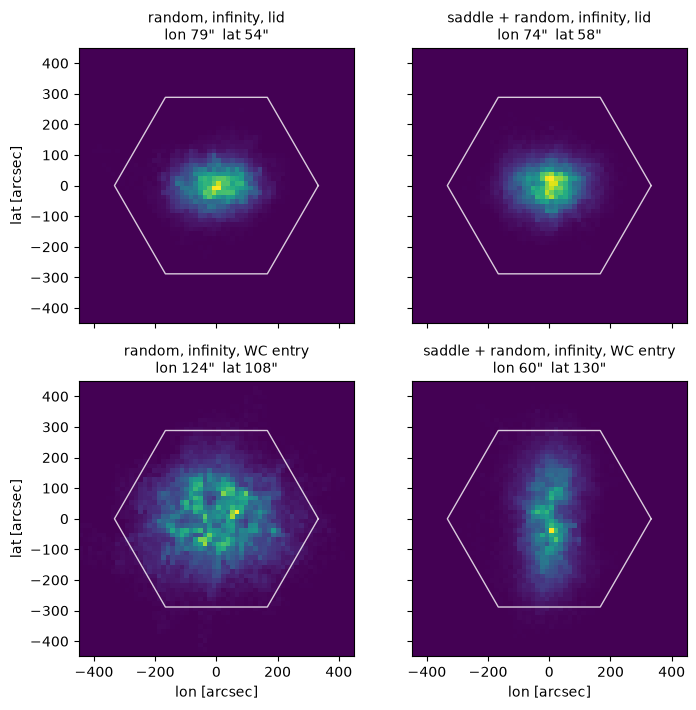

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7.2), sharex=True, sharey=True)
lim = 450
for row, (d, plane) in enumerate([(lid, "lid"), (0.0, "WC entry")]):
    for col, (name, tel) in enumerate(dishes.items()):
        xy, w = spot(tel, d)
        axes[row, col].hist2d(xy[:, 0], xy[:, 1], bins=60, weights=w, range=[[-lim, lim], [-lim, lim]])
        lon, lat = widths(tel, d)
        axes[row, col].set_title(f"{name}, infinity, {plane}\nlon {lon:.0f}\"  lat {lat:.0f}\"", fontsize=10)
        axes[row, col].set_aspect("equal")
        draw_pixel(axes[row, col])
for a in axes[-1]:
    a.set_xlabel("lon [arcsec]")
for a in axes[:, 0]:
    a.set_ylabel("lat [arcsec]")
plt.tight_layout()
plt.show()

These clearly look very different, with the **saddle+random** version actually slimming down in the longitude axis for stars! This is similar to the data we got from differentiable fitting of the NSB at the start.

The explanation for this behaviour is as follows: The coherent bending actually moves the focus point backwards, so that stars at infinity are not focused on the lid anymore, but actually are focused closer to the pixel focal plane (winston cone entry). This actually slims down the star PSF!

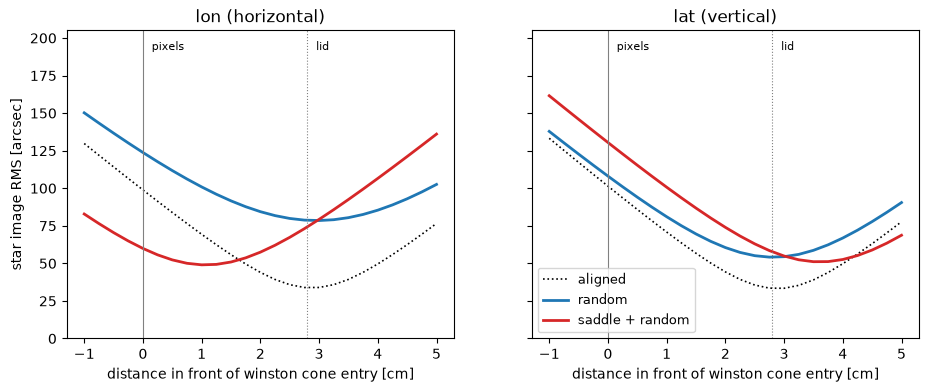

In [5]:
curves = {"aligned": aligned, **dishes}
scan = {name: np.array([widths(tel, d) for d in dz]) for name, tel in curves.items()}
colors = {"aligned": "black", "random": "C0", "saddle + random": "C3"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for name, w in scan.items():
    for k, a in enumerate(axes):
        a.plot(100 * dz, w[:, k], label=name, color=colors[name], lw=1.2 if name == "aligned" else 2,
               ls=":" if name == "aligned" else "-")
for a, axis in zip(axes, ["lon (horizontal)", "lat (vertical)"], strict=False):
    a.axvline(0, color="grey", lw=0.8)
    a.axvline(100 * lid, color="grey", lw=0.8, ls=":")
    a.text(0.15, 192, "pixels", fontsize=8)
    a.text(100 * lid + 0.15, 192, "lid", fontsize=8)
    a.set(xlabel="distance in front of winston cone entry [cm]", title=axis, ylim=(0, 205))
axes[0].set_ylabel("star image RMS [arcsec]")
axes[1].legend(fontsize=9, loc="lower left")
plt.show()

## What is the effect on Cherenkov light?

Cherenkov light does not come from infinity, but from a range between 6 and 15 km. At larger zenith angles, where this saddle effect dominates, it is more towards the upper part of this range. We can check again on how images then differ between the two realizations, but now for point sources at different distances. This gives us a feel how cherenkov images might be affected

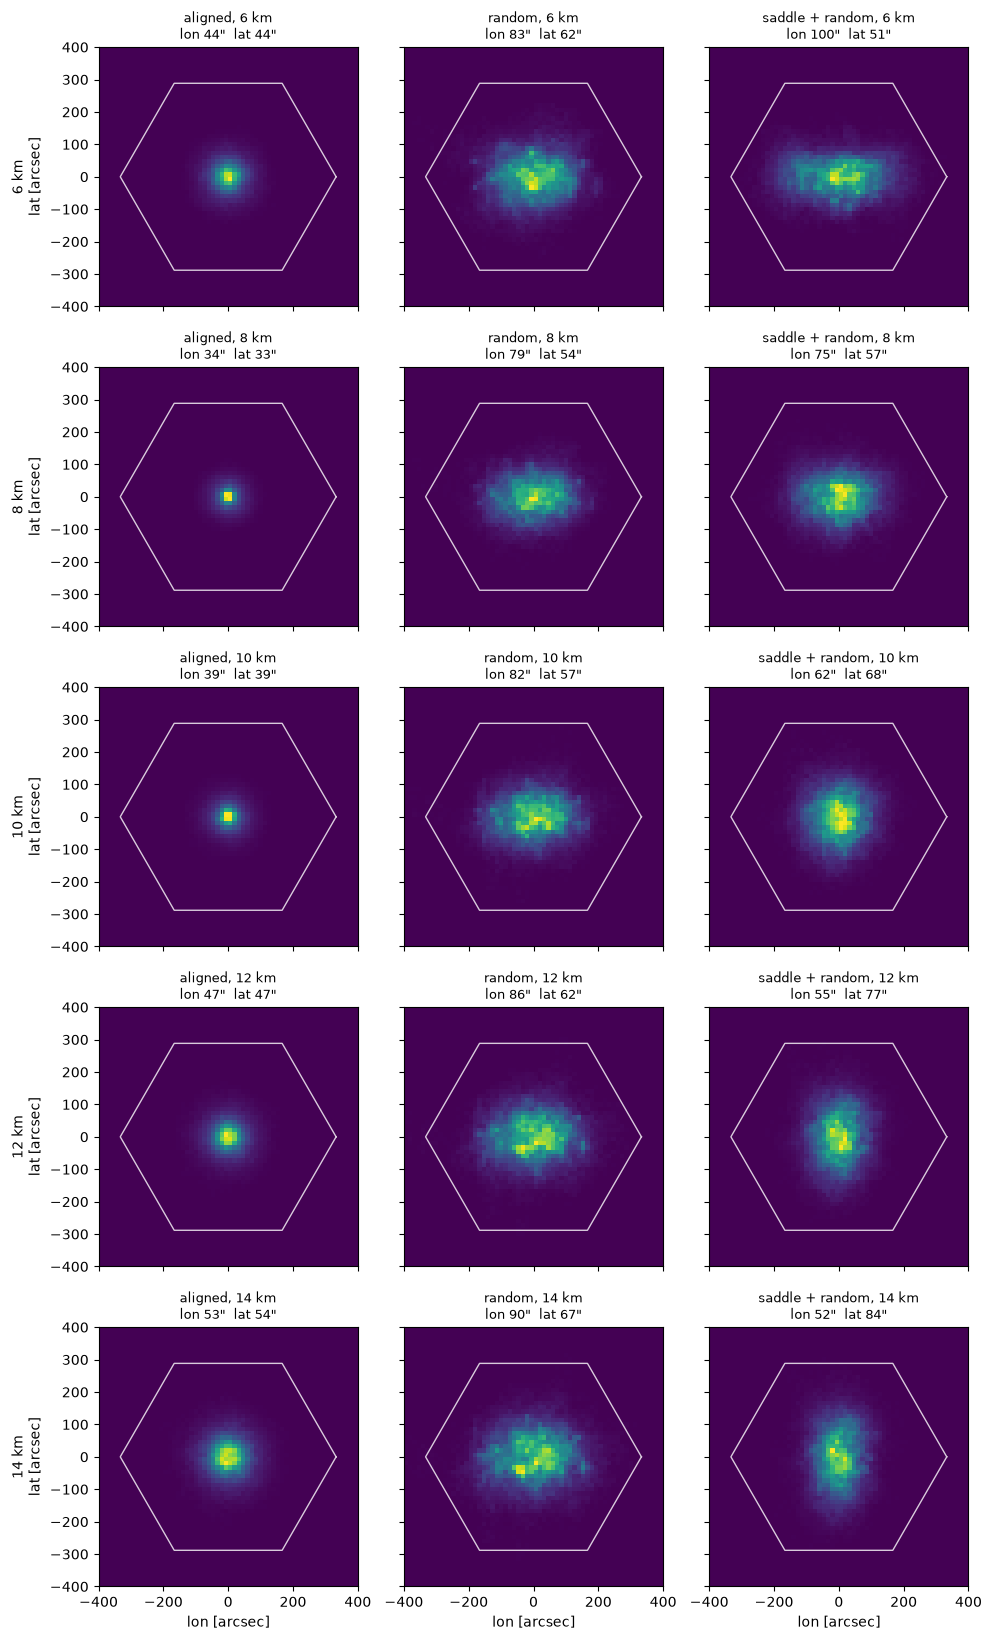

In [6]:
F = 15.0
SHOWER = F * (F + lid) / lid
shower_scan = {name: np.array([widths(tel, d, SHOWER) for d in dz]) for name, tel in curves.items()}
shower_focus = dz[np.argmin(shower_scan["aligned"].mean(axis=1))]
KM = f"{SHOWER / 1000:.1f} km"

DISTANCES = [6000.0, 8000.0, 10000.0, 12000.0, 14000.0]
fig, axes = plt.subplots(len(DISTANCES), 3, figsize=(10, 3.3 * len(DISTANCES)), sharex=True, sharey=True)
lim = 400
for row, d in enumerate(DISTANCES):
    for col, (name, tel) in enumerate(curves.items()):
        xy, w = spot(tel, 0.0, d)
        a = axes[row, col]
        a.hist2d(xy[:, 0], xy[:, 1], bins=60, weights=w, range=[[-lim, lim], [-lim, lim]])
        lon, lat = widths(tel, 0.0, d)
        a.set_title(f"{name}, {d / 1000:.0f} km\nlon {lon:.0f}\"  lat {lat:.0f}\"", fontsize=9)
        a.set_aspect("equal")
        draw_pixel(a)
    axes[row, 0].set_ylabel(f"{d / 1000:.0f} km\nlat [arcsec]")
for a in axes[-1]:
    a.set_xlabel("lon [arcsec]")
plt.tight_layout()
plt.show()

We can check how these two differ with a scan over the entire range:

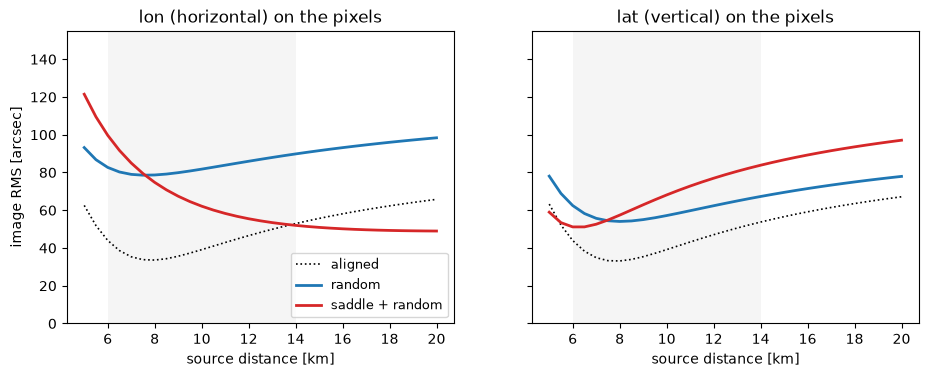

In [8]:
far = np.linspace(5000.0, 20000.0, 31)
trend = {name: np.array([widths(tel, 0.0, d) for d in far]) for name, tel in curves.items()}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for name, w in trend.items():
    for k, a in enumerate(axes):
        a.plot(far / 1000, w[:, k], label=name, color=colors[name], lw=1.2 if name == "aligned" else 2,
               ls=":" if name == "aligned" else "-")
for a, axis in zip(axes, ["lon (horizontal)", "lat (vertical)"], strict=False):
    a.axvspan(6, 14, color="grey", alpha=0.08, lw=0)
    a.set(xlabel="source distance [km]", title=f"{axis} on the pixels", ylim=(0, 155))
axes[0].set_ylabel("image RMS [arcsec]")
axes[0].legend(fontsize=9, loc="lower right")
plt.show()